In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.options.display.max_columns = 500

### Загрузим датасет с машинами. Цель - верно восстанавливать для каждой из них цену продажи!

In [2]:
data = pd.read_csv('autos.csv')

data.head()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
0,Maruti 800 AC,2007,60000,70000,Petrol,Individual,Manual,First Owner
1,Maruti Wagon R LXI Minor,2007,135000,50000,Petrol,Individual,Manual,First Owner
2,Hyundai Verna 1.6 SX,2012,600000,100000,Diesel,Individual,Manual,First Owner
3,Datsun RediGO T Option,2017,250000,46000,Petrol,Individual,Manual,First Owner
4,Honda Amaze VX i-DTEC,2014,450000,141000,Diesel,Individual,Manual,Second Owner


In [3]:
### Колонка с тергетом - "selling price"

X = data.drop("selling_price", axis=1)
y = data["selling_price"]

### Будем замерять MSLE!
### Поэтому прологарифмируем таргет
### А после оптимизируем MSE

y = y.apply(np.log1p)

In [4]:
### Разделим выборку на трейн и тест!

from sklearn.model_selection import train_test_split

object_cols = ['name', 'year', 'fuel', 'seller_type', 'transmission', 'owner']
num_cols = ['km_driven']

X[object_cols] = X[object_cols].astype("object")

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=1)

__Задание__ 

Реализуйте свой MeanTargetEncoder с добавленем некоторого шума!

Однажды в лекционном материале, обсуждая счетчики, мы говорили с вами о том, что из-за них модели могут переобучаться. Один из способов бороться с этим - валидировать расчеты среднего таргета (стратегия отложенной выборки / расчеты на кросс-валидации). Но есть еще проще!

Можно просто к значению счетчика добавить случайный шум (зашумить данные)!

Напомним, что рассчитываться новые признаки должны по такой формуле:

$$
g_j = \frac{\sum_{i=1}^{l} y_i[f_j(x) = f_j(x_i)]}{\sum_{i=1}^{l}[f_j(x) = f_j(x_i)]} + C * \epsilon
$$



Пусть шум будет случайной величиной из нормального стандартного распределения, то есть $\epsilon \sim N(0, 1) $, а $ C = 0.006$.

Создавая свой класс-трансформер, наследуйтесь от классов `BaseEstimator, TransformerMixin` из `sklearn.base`. Трансформер не должен модифицировать передаваемую ему выборку inplace, а все необходимые статистики нужно считать только по обучающей выборке в методе `fit`. Ваш трансформер должен принимать при инициализации список из категориальных признаков и список из числовых признаков. 

Если для какого-то признака в тестовой выборке отсутствует значение, трансформер должен поставить там 0.

На выходе должен получиться датасет того же размера с измененными категориальными признаками.

Класс MeanTargetEncoderNoise должен иметь следующую сигнатуру:



In [5]:
"""
from sklearn.base import BaseEstimator, TransformerMixin

class MeanTargetEncoderNoise(BaseEstimator, TransformerMixin):

    def __init__(self, categorical, numeric):

        ### Your code is here

    def fit(self, X, y):

        ### Your code is here

        return self

    def transform(self, df):

        ### Your code is here

        return temp
"""

'\nfrom sklearn.base import BaseEstimator, TransformerMixin\n\nclass MeanTargetEncoderNoise(BaseEstimator, TransformerMixin):\n\n    def __init__(self, categorical, numeric):\n\n        ### Your code is here\n\n    def fit(self, X, y):\n\n        ### Your code is here\n\n        return self\n\n    def transform(self, df):\n\n        ### Your code is here\n\n        return temp\n'

Разделите колонки на вещественные и категориальные. Приведите все категориальные колонки к типу `object`.

Далее применим наш кодировщик к `X_train, X_test`, так же как например мы применяем `StandardScaler`, чтобы проверить работоспособность нашего класса. Установите зерно датчика случайный чисел `np.random.seed(1)`.

После того, как вы изменили обучающую и тестовую выборки, сохраните первые 10 строк полученного промежуточного датафрейма обучающей выборки (`X_train`) в файл в формате csv с сепаратором `;`. Не забудьте индекс. Отправьте полученный файл в форму ниже.

Список колонок которые должны быть в файле для сдачи:
```py
cols = [
    "km_driven",
    "name",
    "year",
    "fuel",
    "seller_type",
    "transmission",
    "owner"
]
```

### Ваше решение


Разделение колонок на категориальные и числовые.

In [6]:
np.random.seed(1)

X.head()

,name,year,km_driven,fuel,seller_type,transmission,owner
0,Maruti 800 AC,2007,70000,Petrol,Individual,Manual,First Owner
1,Maruti Wagon R LXI Minor,2007,50000,Petrol,Individual,Manual,First Owner
2,Hyundai Verna 1.6 SX,2012,100000,Diesel,Individual,Manual,First Owner
3,Datsun RediGO T Option,2017,46000,Petrol,Individual,Manual,First Owner
4,Honda Amaze VX i-DTEC,2014,141000,Diesel,Individual,Manual,Second Owner


Реализация класса MeanTargetEncoderNoise.

In [7]:
from sklearn.base import BaseEstimator, TransformerMixin

class MeanTargetEncoderNoise(BaseEstimator, TransformerMixin):

    def __init__(self, categorical, numeric):
        self.categorical = categorical
        self.numeric = numeric
        

    def fit(self, X, y):
        self.g_ = {}
        C = 0.006

        for col in self.categorical:
            self.g_[col] = y.groupby(X[col]).apply(lambda x: x.mean() + C * np.random.normal())
        
        return self

    def transform(self, X):
        X = X.copy()
       
        for col in self.categorical:
            d = X[col]
            encoded = d.map(self.g_[col])
            X[col] = encoded.fillna(0)

        return X

Проверка работы трансформера.

In [17]:
cols = ["km_driven", "name", "year", "fuel",
        "seller_type", "transmission", "owner"]

np.random.seed(1)

transformer = MeanTargetEncoderNoise(categorical=object_cols, numeric=num_cols)

transformer.fit(X_train, y_train)

train = transformer.transform(X_train)
test = transformer.transform(X_test)

train[cols].head(10).to_csv("train_head.csv", sep=";", index=False)
train.head(10)

,name,year,km_driven,fuel,seller_type,transmission,owner
3294,13.483692,13.436559,50000,13.093756,12.615863,13.771135,12.977730
2290,12.117029,11.903115,70000,12.453832,12.615863,13.771135,12.977730
874,12.310456,13.328864,50000,12.453832,12.615863,12.639805,12.977730
1907,12.491443,13.042359,92198,12.453832,13.152824,12.639805,12.463313
3244,12.390906,12.870886,3240,12.453832,12.615863,12.639805,12.463313
1089,12.687432,13.436559,10000,12.453832,13.152824,12.639805,12.977730
3902,11.698702,11.503504,90000,12.453832,12.615863,12.639805,11.878390
2215,11.120678,11.503504,79000,12.453832,12.615863,12.639805,12.463313
3862,13.172879,13.328864,99700,13.093756,12.615863,12.639805,12.977730
705,13.004194,12.241213,124000,13.093756,12.615863,12.639805,12.463313


Обучите несколько деревьев, перебирая максимальную глубину алгоритма из списка `max_depth_list`, а остальные параметры оставьте дефолтными. Выведите лучшее значение гиперпараметра. Постройте график зависимости MSLE на тестовой выборке от значения гиперпараметра. Воспользуйтесь `Pipeline` без `GridSearch`. Проделайте то же самое с `min_samples_split`, `min_impurity_decrease`, `max_leaf_nodes`.

In [9]:
max_depth_list = [3, 5, 8, 12]
min_samples_split_list = [10, 50, 100, 500]
min_impurity_decrease_list = [0, 0.1, 0.15, 0.2]
max_leaf_nodes_list = [100, 200, 500]

0.7978271003064045
1.4407231108105145
1.9875843849579033
1.985496900380626
Лучший гиперпараметр max_depth=3


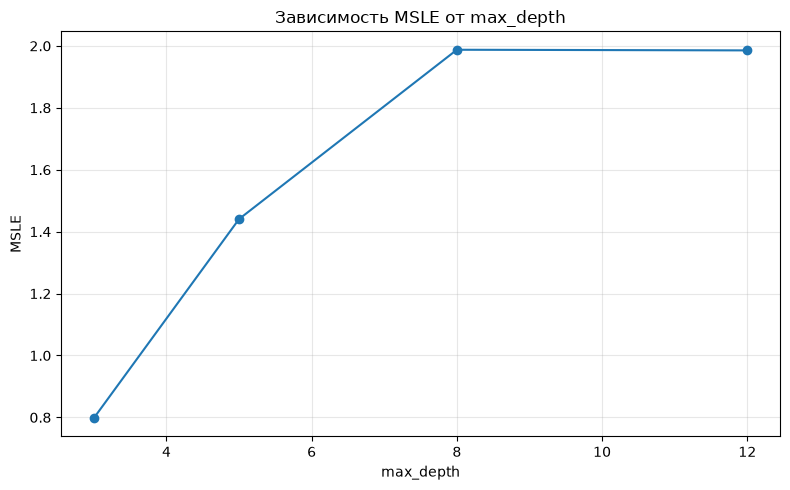

1.4329705887127449
1.4381802535260284
0.9522201881004299
0.807964857221893
Лучший гиперпараметр min_samples_split=500


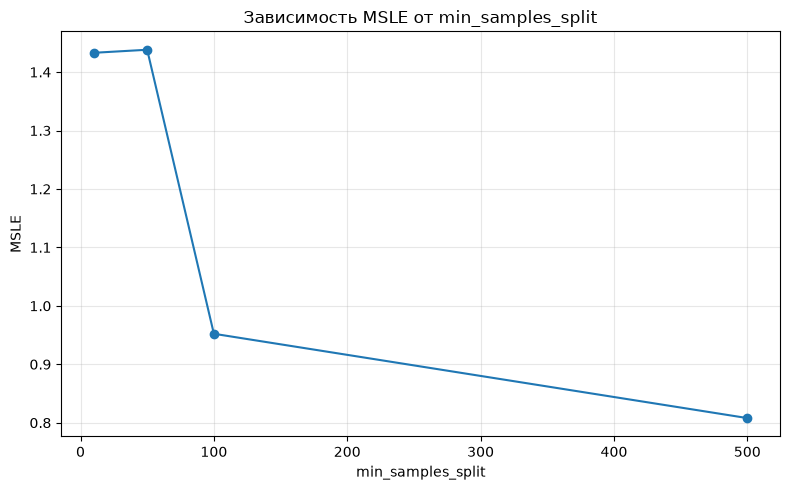

1.9859094606767413
0.5193064743059734
0.5204871413036575
0.5196554863225904
Лучший гиперпараметр min_impurity_decrease=0.1


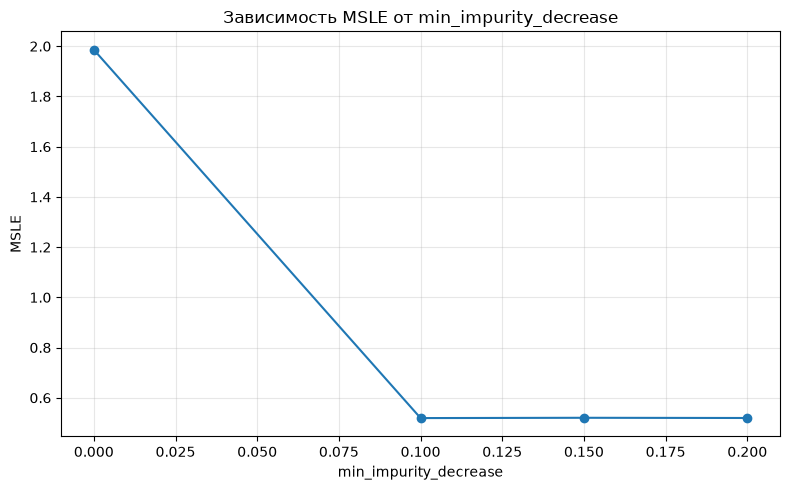

1.9880645922715214
1.9851274144446265
1.985415090495492
Лучший гиперпараметр max_leaf_nodes=200


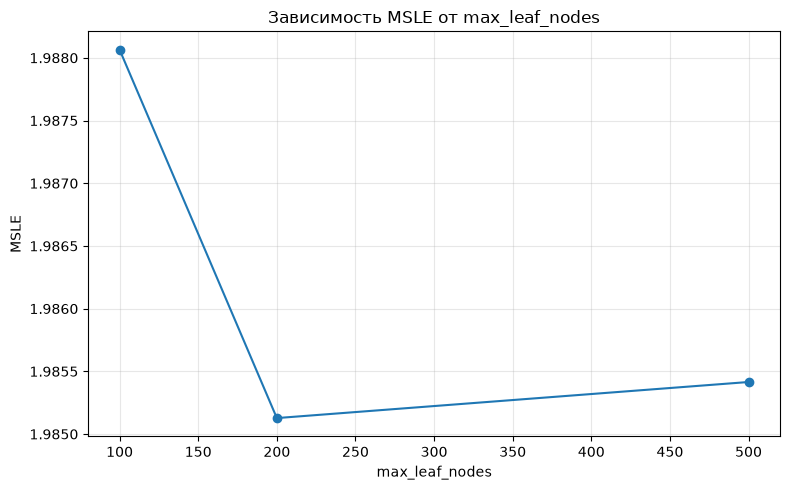

In [10]:
from sklearn.metrics import mean_squared_error as mse
from sklearn.tree import DecisionTreeRegressor
from sklearn.pipeline import Pipeline

np.random.seed(1)

scores = []

for max_depth in max_depth_list:
    pipe = Pipeline([
        ('transformer', MeanTargetEncoderNoise(object_cols, num_cols)),
        ('model', DecisionTreeRegressor(max_depth=max_depth))
    ])

    pipe.fit(X_train, y_train)

    score = mse(y_test, pipe.predict(X_test))
    print(score)
    scores.append(score)

print(f'Лучший гиперпараметр max_depth={max_depth_list[np.argmin(scores)]}')

plt.figure(figsize=(8, 5))
plt.plot(max_depth_list, scores, marker='o')
plt.xlabel('max_depth')
plt.ylabel('MSLE')
plt.title('Зависимость MSLE от max_depth')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


scores = []

for min_samples_split in min_samples_split_list:
    pipe = Pipeline([
        ('transformer', MeanTargetEncoderNoise(object_cols, num_cols)),
        ('model', DecisionTreeRegressor(min_samples_split=min_samples_split))
    ])

    pipe.fit(X_train, y_train)

    score = mse(y_test, pipe.predict(X_test))
    print(score)
    scores.append(score)

print(f'Лучший гиперпараметр min_samples_split={min_samples_split_list[np.argmin(scores)]}')

plt.figure(figsize=(8, 5))
plt.plot(min_samples_split_list, scores, marker='o')
plt.xlabel('min_samples_split')
plt.ylabel('MSLE')
plt.title('Зависимость MSLE от min_samples_split')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


scores = []

for min_impurity_decrease in min_impurity_decrease_list:
    pipe = Pipeline([
        ('transformer', MeanTargetEncoderNoise(object_cols, num_cols)),
        ('model', DecisionTreeRegressor(min_impurity_decrease=min_impurity_decrease))
    ])

    pipe.fit(X_train, y_train)

    score = mse(y_test, pipe.predict(X_test))
    print(score)
    scores.append(score)

print(f'Лучший гиперпараметр min_impurity_decrease={min_impurity_decrease_list[np.argmin(scores)]}')

plt.figure(figsize=(8, 5))
plt.plot(min_impurity_decrease_list, scores, marker='o')
plt.xlabel('min_impurity_decrease')
plt.ylabel('MSLE')
plt.title('Зависимость MSLE от min_impurity_decrease')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


scores = []

for max_leaf_nodes in max_leaf_nodes_list:
    pipe = Pipeline([
        ('transformer', MeanTargetEncoderNoise(object_cols, num_cols)),
        ('model', DecisionTreeRegressor(max_leaf_nodes=max_leaf_nodes))
    ])

    pipe.fit(X_train, y_train)

    score = mse(y_test, pipe.predict(X_test))
    print(score)
    scores.append(score)

print(f'Лучший гиперпараметр max_leaf_nodes={max_leaf_nodes_list[np.argmin(scores)]}')

plt.figure(figsize=(8, 5))
plt.plot(max_leaf_nodes_list, scores, marker='o')
plt.xlabel('max_leaf_nodes')
plt.ylabel('MSLE')
plt.title('Зависимость MSLE от max_leaf_nodes')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Подберите лучшую комбинацию параметров, используя `GridSearchCV` и набор массивов значений параметров из предыдущего задания. Для лучшей комбинации посчитайте MSLE на тестовой выборке. Получились ли лучшие параметры такими же, как если бы вы подбирали их по-отдельности при остальных гиперпараметрах по умолчанию (предыдущее задание)? (2б)

In [11]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "decision_tree__max_depth": [3, 5, 8, 12],
    "decision_tree__min_samples_split": [10, 50, 100, 500],
    "decision_tree__min_impurity_decrease": [0, 0.1, 0.15, 0.2],
    "decision_tree__max_leaf_nodes": [100, 200, 500]
}
np.random.seed(1)

pipe = Pipeline([
    ('transformer', MeanTargetEncoderNoise(object_cols, num_cols)),
    ('decision_tree', DecisionTreeRegressor())
])

grid = GridSearchCV(pipe, param_grid, cv=4, scoring='neg_mean_squared_error')
grid.fit(X_train, y_train)

print(grid.best_params_)
print(mse(y_test, grid.best_estimator_.predict(X_test)))


{'decision_tree__max_depth': 12, 'decision_tree__max_leaf_nodes': 100, 'decision_tree__min_impurity_decrease': 0.2, 'decision_tree__min_samples_split': 10}
0.5197845418971017
